Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 926us/step - accuracy: 0.7174 - loss: 1.1733 - val_accuracy: 0.8519 - val_loss: 0.6438
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 770us/step - accuracy: 0.8637 - loss: 0.5548 - val_accuracy: 0.8852 - val_loss: 0.4561
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 738us/step - accuracy: 0.8838 - loss: 0.4414 - val_accuracy: 0.8964 - val_loss: 0.3898
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 718us/step - accuracy: 0.8940 - loss: 0.3908 - val_accuracy: 0.9033 - val_loss: 0.3529
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 711us/step - accuracy: 0.9003 - loss: 0.3605 - val_accuracy: 0.9087 - val_loss: 0.3303
Test Loss: 0.33034804463386536
Test Accuracy: 0.9086999893188477


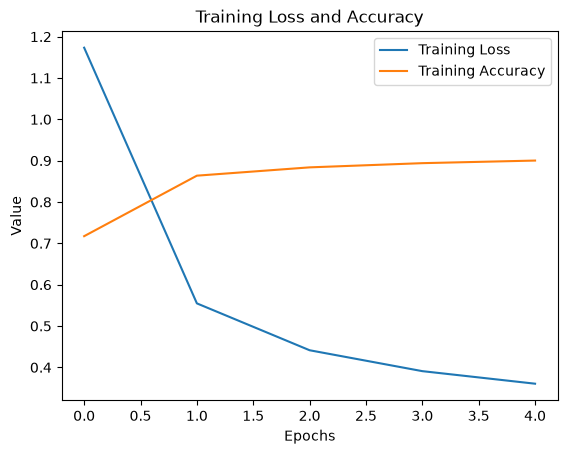

In [19]:

import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.optimizers import SGD

# 1. Load dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Normalize data
x_train, x_test = x_train / 255.0, x_test / 255.0

# 3. Define network
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# 4. Compile and train using SGD
model.compile(optimizer=SGD(learning_rate=0.01),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    validation_data=(x_test, y_test),
                    epochs=5, batch_size=128)

# 5. Evaluate network
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 6. Plot training loss and accuracy
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Value')
plt.title('Training Loss and Accuracy')
plt.legend()
plt.show()
